# 01 — Titanic: exploratory data analysis

This notebook profiles the Titanic passenger data, makes missing-data decisions explicit, compares outcomes across passenger groups, and ends with findings computed from the loaded data.

**Questions:** How complete and consistent are the fields? Which passenger characteristics are associated with survival? What does the evidence suggest, and what should not be inferred from these observational data?

The notebook looks for a CSV in the working directory, `data/`, or `analytics/`. If none is present, it reads the standard Titanic CSV used by seaborn from GitHub; that first download requires internet access. No target-derived field (such as `alive`) is used as a predictor here.

In [1]:
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(context="notebook", style="whitegrid")


In [2]:

from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
LOCAL_DATA_CANDIDATES = [
    Path("titanic.csv"),
    Path("data/titanic.csv"),
    Path("analytics/titanic.csv"),
    Path("analytics/data/titanic.csv"),
]

local_data = next((path for path in LOCAL_DATA_CANDIDATES if path.is_file()), None)
if local_data is None:
    titanic = pd.read_csv(DATA_URL)
    DATA_SOURCE = DATA_URL
else:
    titanic = pd.read_csv(local_data)
    DATA_SOURCE = str(local_data.resolve())

titanic.columns = titanic.columns.str.lower()
required_columns = {
    "survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"
}
missing_columns = required_columns.difference(titanic.columns)
if missing_columns:
    raise ValueError(f"Titanic data is missing required columns: {sorted(missing_columns)}")

print(f"Loaded {len(titanic):,} rows from {DATA_SOURCE}")


Loaded 891 rows from C:\zepto-data-ai-platform\analytics\titanic.csv


## 1. Data profile

The `survived` column is the binary outcome (1 = survived, 0 = did not survive). The remaining columns describe passengers and travel circumstances.

In [3]:
print(f"Rows: {titanic.shape[0]:,} | Columns: {titanic.shape[1]}")
display(titanic.head())

profile = pd.DataFrame(
    {
        "dtype": titanic.dtypes.astype(str),
        "non_null": titanic.notna().sum(),
        "missing": titanic.isna().sum(),
        "missing_pct": (titanic.isna().mean() * 100).round(1),
        "distinct": titanic.nunique(dropna=True),
    }
).sort_values(["missing", "distinct"], ascending=[False, False])
display(profile)
print(f"Exact duplicate rows: {titanic.duplicated().sum():,}")


Rows: 891 | Columns: 15


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


,dtype,non_null,missing,missing_pct,distinct
deck,str,203,688,77.2,7
age,float64,714,177,19.9,88
embarked,str,889,2,0.2,3
embark_town,str,889,2,0.2,3
fare,float64,891,0,0.0,248
sibsp,int64,891,0,0.0,7
parch,int64,891,0,0.0,7
pclass,int64,891,0,0.0,3
class,str,891,0,0.0,3
who,str,891,0,0.0,3


Exact duplicate rows: 107


## 2. Missing-value handling rules

For descriptive analysis, keep the original `titanic` frame unchanged and use the explicitly cleaned `eda` copy below.

| Field | Rule | Reason |
|---|---|---|
| `age` | Fill with the median within passenger class and sex; use the overall median only if a group has no observed ages. | Preserves broad age differences between groups and avoids turning unknown age into age zero. |
| `embarked` | Fill missing values with the most frequent port. | A small number of missing categorical values; mode is a transparent simple rule. |
| `deck` / `cabin` | Preserve a missingness indicator; do not impute a fictional deck or cabin. Exclude the raw field from the baseline modeling features. | Cabin/deck is heavily incomplete and missingness may itself carry information. |
| Other fields | Report missingness; do not silently drop rows or fill them here. | Keeps decisions visible and tied to the analysis question. |

These are pragmatic descriptive rules, not a claim that missingness is random. Modeling preprocessing is kept separate and fit only on training data in `02_modeling.ipynb`.

In [4]:
missingness = (
    titanic.isna()
    .agg(["sum", "mean"])
    .T.rename(columns={"sum": "missing_count", "mean": "missing_fraction"})
    .sort_values("missing_count", ascending=False)
)
missingness["missing_pct"] = (100 * missingness["missing_fraction"]).round(1)
display(missingness[["missing_count", "missing_pct"]])

cabin_column = next((column for column in ("cabin", "deck") if column in titanic), None)
eda = titanic.copy()
if cabin_column is not None:
    eda["has_cabin_or_deck"] = eda[cabin_column].notna()
else:
    eda["has_cabin_or_deck"] = False

age_group_median = eda.groupby(["pclass", "sex"], observed=True)["age"].transform("median")
eda["age"] = eda["age"].fillna(age_group_median).fillna(eda["age"].median())
if eda["embarked"].notna().any():
    eda["embarked"] = eda["embarked"].fillna(eda["embarked"].mode().iloc[0])

print("Remaining missing values after the documented descriptive rules:")
display(eda.isna().sum().loc[lambda values: values.gt(0)])


,missing_count,missing_pct
deck,688.0,77.2
age,177.0,19.9
embarked,2.0,0.2
embark_town,2.0,0.2
sex,0.0,0.0
pclass,0.0,0.0
survived,0.0,0.0
fare,0.0,0.0
parch,0.0,0.0
sibsp,0.0,0.0


Remaining missing values after the documented descriptive rules:


deck           688
embark_town      2
dtype: int64

## 3. Univariate analysis

First inspect outcome balance and the distributions of key numeric and categorical fields.

,count,mean,std,min,25%,50%,75%,max
survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
age,891.0,29.112424,13.304424,0.42,21.5000,26.0000,36.0,80.0000
fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292
pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
sibsp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000


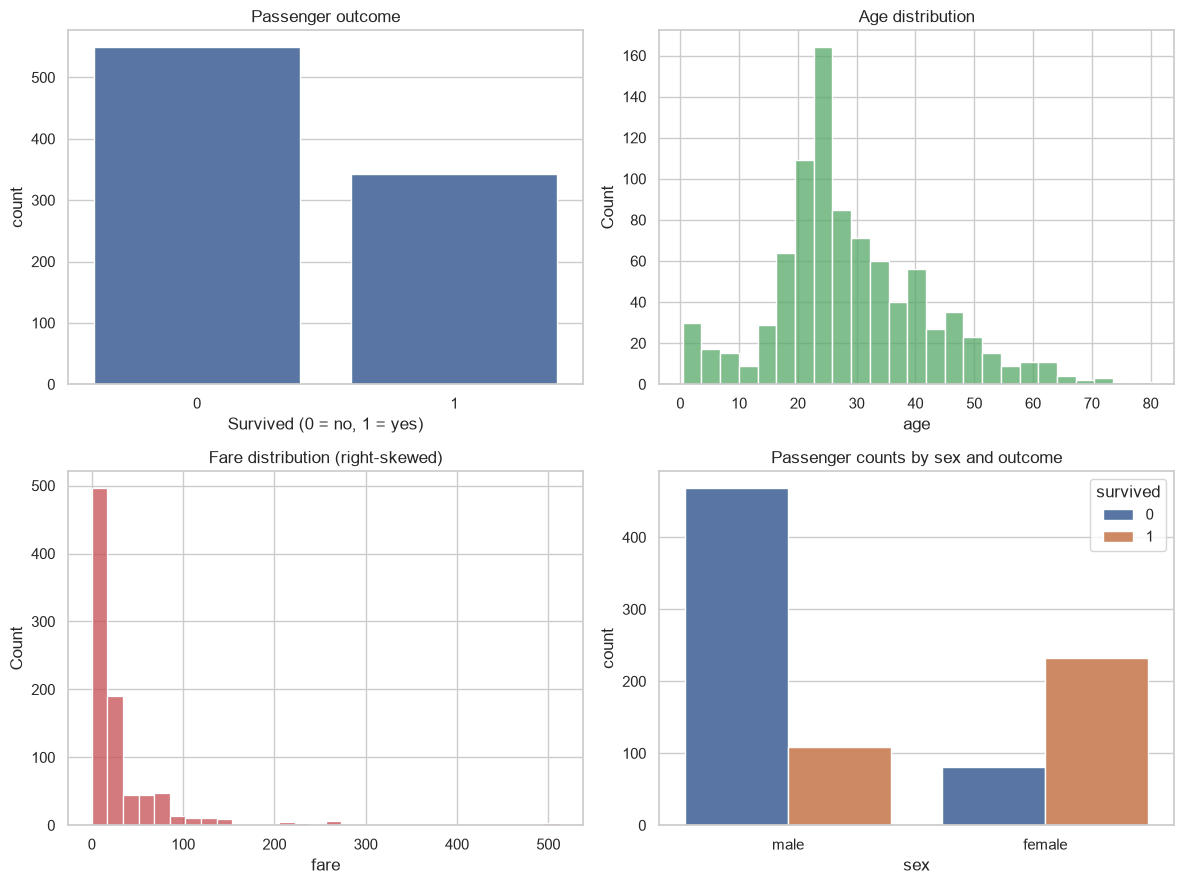

,passengers
pclass,
1,216
2,184
3,491


,passengers
sex,
male,577
female,314


In [5]:
display(eda[["survived", "age", "fare", "pclass", "sibsp", "parch"]].describe().T)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
sns.countplot(data=eda, x="survived", ax=axes[0, 0], color="#4c72b0")
axes[0, 0].set(title="Passenger outcome", xlabel="Survived (0 = no, 1 = yes)")
sns.histplot(data=eda, x="age", bins=25, ax=axes[0, 1], color="#55a868")
axes[0, 1].set(title="Age distribution")
sns.histplot(data=eda, x="fare", bins=30, ax=axes[1, 0], color="#c44e52")
axes[1, 0].set(title="Fare distribution (right-skewed)")
sns.countplot(data=eda, x="sex", hue="survived", ax=axes[1, 1])
axes[1, 1].set(title="Passenger counts by sex and outcome")
fig.tight_layout()
plt.show()

display(eda["pclass"].value_counts().sort_index().rename("passengers").to_frame())
display(eda["sex"].value_counts().rename("passengers").to_frame())


## 4. Bivariate analysis

Compare survival rates, not only raw counts: group sizes differ substantially. These are associations in the observed passenger records, not causal effects.

,passengers,survival_rate
sex,,
female,314,74.2%
male,577,18.9%


,passengers,survival_rate
pclass,,
1,216,63.0%
2,184,47.3%
3,491,24.2%


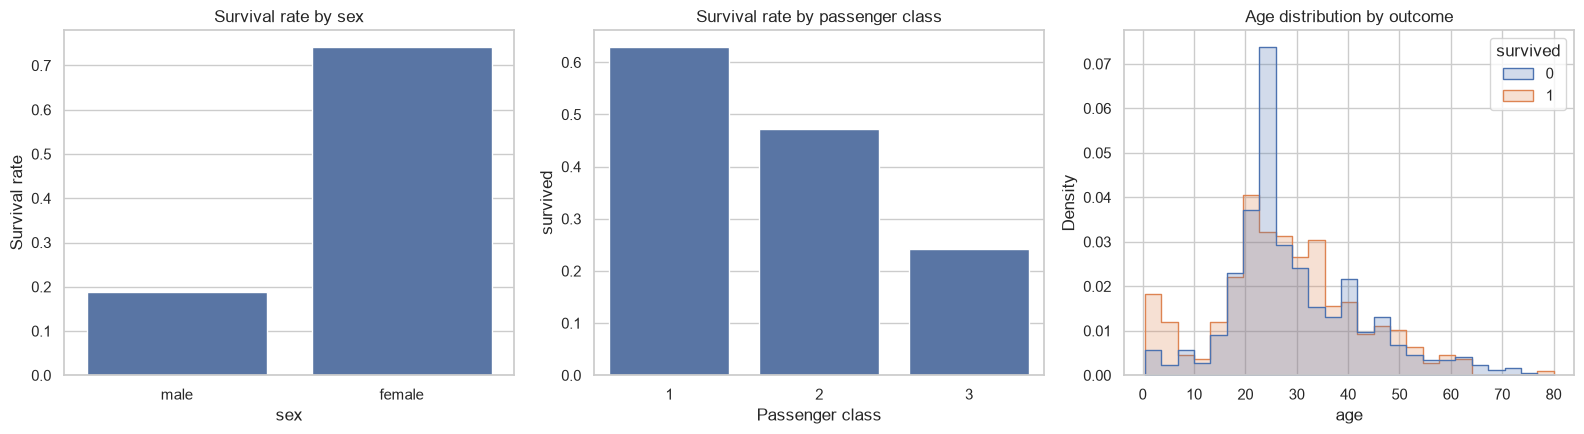

,passengers,median_fare,mean_fare
survived,,,
0,549,10.5,22.12
1,342,26.0,48.40


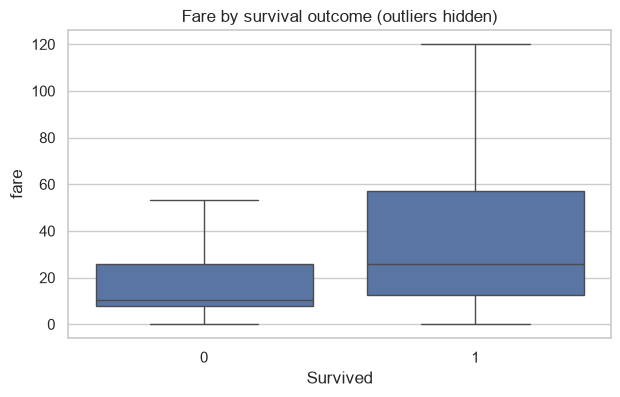

In [6]:
survival_by_sex = (
    eda.groupby("sex", observed=True)["survived"]
    .agg(passengers="size", survival_rate="mean")
    .sort_values("survival_rate", ascending=False)
)
survival_by_class = (
    eda.groupby("pclass", observed=True)["survived"]
    .agg(passengers="size", survival_rate="mean")
    .sort_index()
)
display(survival_by_sex.style.format({"survival_rate": "{:.1%}"}))
display(survival_by_class.style.format({"survival_rate": "{:.1%}"}))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.barplot(data=eda, x="sex", y="survived", errorbar=None, ax=axes[0])
axes[0].set(title="Survival rate by sex", ylabel="Survival rate")
sns.barplot(data=eda, x="pclass", y="survived", errorbar=None, ax=axes[1])
axes[1].set(title="Survival rate by passenger class", xlabel="Passenger class")
sns.histplot(data=eda, x="age", hue="survived", bins=25, stat="density",
             common_norm=False, element="step", ax=axes[2])
axes[2].set(title="Age distribution by outcome")
fig.tight_layout()
plt.show()

fare_summary = eda.groupby("survived", observed=True)["fare"].agg(
    passengers="size", median_fare="median", mean_fare="mean"
)
display(fare_summary.round(2))
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=eda, x="survived", y="fare", showfliers=False, ax=ax)
ax.set(title="Fare by survival outcome (outliers hidden)", xlabel="Survived")
plt.show()

class_sex_table = pd.crosstab(
    [eda["pclass"], eda["sex"]], eda["survived"], normalize="index"
).rename(columns={0: "did_not_survive", 1: "survived"})
display(class_sex_table.style.format("{:.1%}"))


## 5. Data story

The statements below are calculated from the loaded dataset. Read them as descriptive patterns; passenger records alone do not establish why a difference exists.

In [7]:
overall_rate = eda["survived"].mean()
sex_rates = eda.groupby("sex", observed=True)["survived"].mean().sort_values(ascending=False)
class_rates = eda.groupby("pclass", observed=True)["survived"].mean()
age_medians = eda.groupby("survived", observed=True)["age"].median()
fare_medians = eda.groupby("survived", observed=True)["fare"].median()

print(f"Overall, {overall_rate:.1%} of records are labeled as survivors.")
if len(sex_rates) >= 2:
    print(
        f"The highest observed survival rate by sex is for {sex_rates.index[0]} "
        f"({sex_rates.iloc[0]:.1%}); the lowest is for {sex_rates.index[-1]} "
        f"({sex_rates.iloc[-1]:.1%})."
    )
if len(class_rates) >= 2:
    print(
        f"Among passenger classes, class {class_rates.idxmax()} has the highest "
        f"observed survival rate ({class_rates.max():.1%}) and class "
        f"{class_rates.idxmin()} the lowest ({class_rates.min():.1%})."
    )
if 0 in age_medians.index and 1 in age_medians.index:
    print(
        f"Median age is {age_medians.loc[1]:.1f} among survivors and "
        f"{age_medians.loc[0]:.1f} among non-survivors."
    )
if 0 in fare_medians.index and 1 in fare_medians.index:
    print(
        f"Median fare is {fare_medians.loc[1]:.2f} among survivors and "
        f"{fare_medians.loc[0]:.2f} among non-survivors."
    )

print(
    "\nInterpretation: class, sex, age, and fare show descriptive differences in "
    "this sample. They are correlated characteristics, so these comparisons do "
    "not isolate causal effects or guarantee individual outcomes."
)


Overall, 38.4% of records are labeled as survivors.
The highest observed survival rate by sex is for female (74.2%); the lowest is for male (18.9%).
Among passenger classes, class 1 has the highest observed survival rate (63.0%) and class 3 the lowest (24.2%).
Median age is 27.0 among survivors and 25.0 among non-survivors.
Median fare is 26.00 among survivors and 10.50 among non-survivors.

Interpretation: class, sex, age, and fare show descriptive differences in this sample. They are correlated characteristics, so these comparisons do not isolate causal effects or guarantee individual outcomes.
